# Drift en modelos de Machine Learning
## Un ejemplo sencillo: la heladería

Un modelo aprende con datos del **pasado**. Si el mundo cambia, el modelo puede quedar desactualizado. A ese cambio se le llama **drift** (deriva).

Hay dos tipos:

| | **Data drift** (cambian los datos) | **Concept drift** (cambia la regla) |
|---|---|---|
| ¿Qué cambia? | Los datos que entran al modelo | La relación entre los datos y el resultado |
| Ejemplo | Llega el verano: hace más calor | Sube el precio: con el mismo calor se venden menos helados |
| ¿Cómo se detecta? | Comparando los datos nuevos con los de entrenamiento | Comparando lo que predijo el modelo con lo que pasó de verdad |
| ¿Daña al modelo? | A veces sí, a veces no | Casi siempre |
| ¿Qué hacer? | Vigilar | Reentrenar el modelo |

### La historia

Una heladería tiene un modelo que **predice cuántos helados va a vender en el día según la temperatura**. Con eso decide cuánto helado preparar.

| Momento | Qué pasa | Tipo de drift |
|---|---|---|
| Primavera | Se entrena el modelo | — |
| Verano | Hace más calor | **Data drift** |
| Verano, con precio nuevo | Sube el precio del helado | **Concept drift** |

In [7]:
import numpy as np                                   # números aleatorios y cálculos
import matplotlib.pyplot as plt                      # gráficos
from scipy.stats import ks_2samp                     # prueba para comparar dos grupos de datos
from sklearn.linear_model import LinearRegression    # el modelo: una regresión lineal (una recta)
from sklearn.metrics import mean_absolute_error      # el error promedio del modelo

---
## Paso 1 · Simular el mundo

Esta función hace de **realidad**: dice cuántos helados se venden según la temperatura. En la vida real no la conocemos; solo vemos sus resultados.

- **Precio normal:** cada grado más de calor se venden 8 helados más.
- **Precio alto:** cada grado más se venden solo 5 helados más, y hay menos clientes.

In [8]:
rng = np.random.default_rng(42)                      # generador de azar con semilla fija (siempre da lo mismo)

def vender_helados(temperaturas, precio_alto=False):
    ruido = rng.normal(0, 10, len(temperaturas))     # el azar de cada día (±10 helados aprox.)
    if precio_alto:                                  # si el precio subió...
        return 5 * temperaturas - 40 + ruido         # ...la regla cambia: se vende menos
    return 8 * temperaturas - 60 + ruido             # regla normal: 8 helados más por cada grado

---
## Paso 2 · Primavera: entrenar el modelo

Tenemos 100 días de primavera, con una temperatura promedio de 20 °C.

In [9]:
temp_primavera = rng.normal(20, 3, 100)              # 100 días, promedio 20 °C, variación ±3 °C
ventas_primavera = vender_helados(temp_primavera)    # cuántos helados se vendieron cada día

modelo = LinearRegression()                          # creamos el modelo (una recta)
modelo.fit(temp_primavera.reshape(-1, 1),            # lo entrenamos: temperatura (en columna, como pide sklearn)...
           ventas_primavera)                         # ...y ventas reales

print(f"El modelo aprendió: ventas = {modelo.coef_[0]:.1f} × temperatura {modelo.intercept_:+.1f}")

El modelo aprendió: ventas = 8.4 × temperatura -68.0


¿Qué tan bien predice? Usamos el **error promedio**: cuántos helados se equivoca, en promedio, cada día. Este número es nuestra **referencia**: lo que esperamos del modelo.

In [10]:
prediccion = modelo.predict(temp_primavera.reshape(-1, 1))             # lo que el modelo predice
error_referencia = mean_absolute_error(ventas_primavera, prediccion)   # error promedio (en helados)
print(f"Error de referencia: {error_referencia:.1f} helados por día")

Error de referencia: 7.8 helados por día


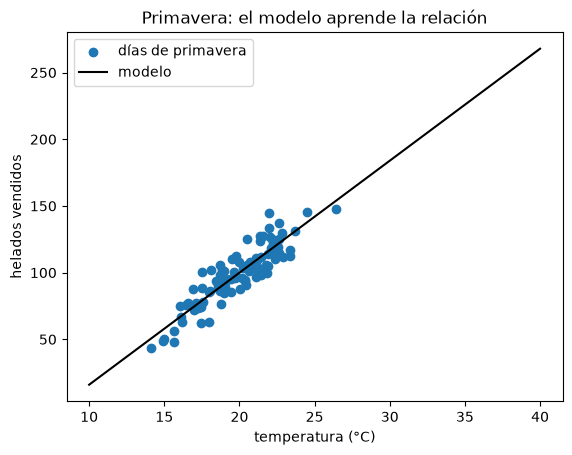

In [11]:
x = np.linspace(10, 40, 100)                                       # temperaturas de 10 a 40 °C para dibujar la recta

plt.scatter(temp_primavera, ventas_primavera, label="días de primavera")        # cada punto es un día
plt.plot(x, modelo.predict(x.reshape(-1, 1)), color="black", label="modelo")    # la recta que aprendió
plt.xlabel("temperatura (°C)")                                     # nombre del eje x
plt.ylabel("helados vendidos")                                     # nombre del eje y
plt.title("Primavera: el modelo aprende la relación")              # título
plt.legend()                                                       # leyenda
plt.show()                                                         # mostrar el gráfico

---
## Paso 3 · Llega el verano → DATA DRIFT

Ahora la temperatura promedio es 30 °C. **La regla no cambió**: cada grado sigue sumando 8 helados.

In [12]:
temp_verano = rng.normal(30, 3, 100)                 # 100 días de verano, promedio 30 °C
ventas_verano = vender_helados(temp_verano)          # ventas reales (misma regla de siempre)

### 3.1 · ¿Cambiaron los datos?

Comparamos las temperaturas del verano con las de primavera (las del entrenamiento). Primero, con un gráfico:

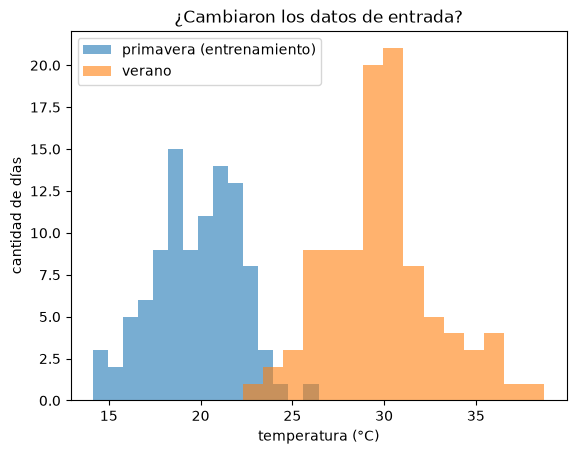

In [13]:
plt.hist(temp_primavera, bins=15, alpha=0.6, label="primavera (entrenamiento)")   # temperaturas de primavera
plt.hist(temp_verano, bins=15, alpha=0.6, label="verano")                         # temperaturas de verano
plt.xlabel("temperatura (°C)")                                                    # nombre del eje x
plt.ylabel("cantidad de días")                                                    # nombre del eje y
plt.title("¿Cambiaron los datos de entrada?")                                     # título
plt.legend()                                                                      # leyenda
plt.show()                                                                        # mostrar

Se ve a simple vista que los datos se movieron. Para decidirlo con un número usamos la **prueba de Kolmogórov-Smirnov (KS)**, que compara dos grupos de datos:

- **p-valor menor a 0.05** → los dos grupos son distintos → **hay data drift**.
- **p-valor mayor a 0.05** → no hay evidencia de cambio.

In [14]:
p_valor = ks_2samp(temp_primavera, temp_verano).pvalue   # compara las dos listas de temperaturas
print(f"p-valor = {p_valor:.2g}")                        # mostramos el p-valor
print("¿Hay data drift?", "SÍ" if p_valor < 0.05 else "NO")

p-valor = 1.4e-51
¿Hay data drift? SÍ


### 3.2 · ¿El modelo sigue acertando?

Al final de cada día sabemos cuántos helados se vendieron de verdad. Comparamos con lo que predijo el modelo:

In [15]:
prediccion_verano = modelo.predict(temp_verano.reshape(-1, 1))           # lo que predijo el modelo
error_verano = mean_absolute_error(ventas_verano, prediccion_verano)     # cuánto se equivocó
print(f"Error en primavera (referencia): {error_referencia:.1f} helados")
print(f"Error en verano:                 {error_verano:.1f} helados")

Error en primavera (referencia): 7.8 helados
Error en verano:                 8.3 helados


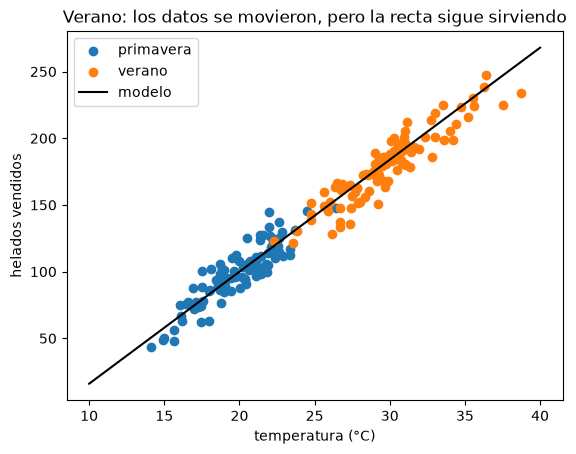

In [16]:
plt.scatter(temp_primavera, ventas_primavera, label="primavera")         # puntos de primavera
plt.scatter(temp_verano, ventas_verano, label="verano")                  # puntos de verano
plt.plot(x, modelo.predict(x.reshape(-1, 1)), color="black", label="modelo")   # la misma recta de antes
plt.xlabel("temperatura (°C)")
plt.ylabel("helados vendidos")
plt.title("Verano: los datos se movieron, pero la recta sigue sirviendo")
plt.legend()
plt.show()

**Conclusión del verano:**

- Los datos **sí** cambiaron (más calor) → hay **data drift**.
- Pero el modelo **sigue acertando**: los puntos del verano caen sobre la misma recta.
- **Acción:** no hace falta reentrenar, solo **vigilar**.

> El data drift no siempre es un problema. Lo importante es si el modelo sigue acertando.

---
## Paso 4 · Sube el precio → CONCEPT DRIFT

Sigue siendo verano (30 °C en promedio), pero el helado ahora es más caro. **Con la misma temperatura, la gente compra menos.** Cambió la regla.

In [17]:
temp_precio = rng.normal(30, 3, 100)                             # 100 días más de verano, promedio 30 °C
ventas_precio = vender_helados(temp_precio, precio_alto=True)    # ventas con la regla NUEVA

### 4.1 · ¿Cambiaron los datos?

Comparamos las temperaturas de estos días con las del verano anterior:

In [18]:
p_valor = ks_2samp(temp_verano, temp_precio).pvalue                     # compara verano vs verano con precio nuevo
print(f"Temperatura promedio: verano {temp_verano.mean():.1f} °C · con precio nuevo {temp_precio.mean():.1f} °C")
print(f"p-valor = {p_valor:.2f}")                                       # mostramos el p-valor
print("¿Cambiaron los datos?", "SÍ" if p_valor < 0.05 else "NO")

Temperatura promedio: verano 29.8 °C · con precio nuevo 29.9 °C
p-valor = 0.70
¿Cambiaron los datos? NO


**Los datos de entrada no cambiaron.** Si solo miráramos la temperatura, diríamos que todo está bien.

### 4.2 · ¿El modelo sigue acertando?

In [19]:
prediccion_precio = modelo.predict(temp_precio.reshape(-1, 1))           # lo que predijo el modelo
error_precio = mean_absolute_error(ventas_precio, prediccion_precio)     # cuánto se equivocó
print(f"Error de referencia:      {error_referencia:.1f} helados")
print(f"Error con precio nuevo:   {error_precio:.1f} helados")
print(f"Ventas promedio predichas: {prediccion_precio.mean():.0f} · ventas reales: {ventas_precio.mean():.0f}")

Error de referencia:      7.8 helados
Error con precio nuevo:   74.4 helados
Ventas promedio predichas: 183 · ventas reales: 108


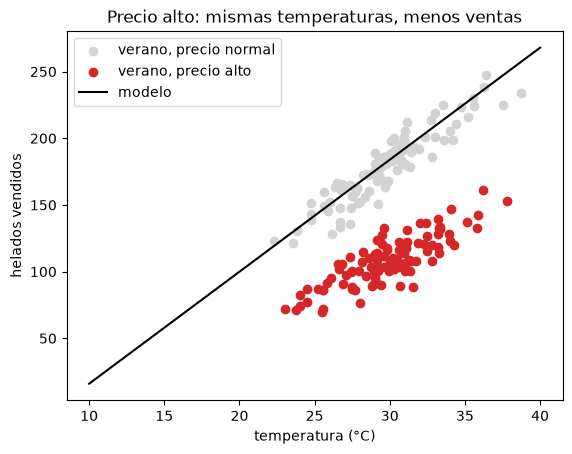

In [20]:
plt.scatter(temp_verano, ventas_verano, color="lightgray", label="verano, precio normal")   # antes (en gris)
plt.scatter(temp_precio, ventas_precio, color="tab:red", label="verano, precio alto")      # ahora (en rojo)
plt.plot(x, modelo.predict(x.reshape(-1, 1)), color="black", label="modelo")               # la recta vieja
plt.xlabel("temperatura (°C)")
plt.ylabel("helados vendidos")
plt.title("Precio alto: mismas temperaturas, menos ventas")
plt.legend()
plt.show()

**Conclusión del precio nuevo:**

- Los datos de entrada **no** cambiaron: la temperatura es la misma.
- Pero el modelo se equivoca **muchísimo**: predice unos 180 helados y se venden unos 110. La heladería prepararía helado de más y lo perdería.
- La recta negra quedó por encima de los puntos rojos: **cambió la regla** entre temperatura y ventas. Eso es **concept drift**.
- Solo lo descubrimos al comparar **la predicción con las ventas reales**.

---
## Paso 5 · Reentrenar el modelo

Ante concept drift, el modelo tiene que **aprender la regla nueva**. Lo entrenamos con los días que ya tienen el precio nuevo y lo probamos con días que no ha visto.

In [21]:
modelo_nuevo = LinearRegression()                                    # un modelo nuevo
modelo_nuevo.fit(temp_precio.reshape(-1, 1), ventas_precio)          # aprende con los datos del precio nuevo

temp_prueba = rng.normal(30, 3, 100)                                 # 100 días nuevos para probar
ventas_prueba = vender_helados(temp_prueba, precio_alto=True)        # ventas reales de esos días

error_viejo = mean_absolute_error(ventas_prueba, modelo.predict(temp_prueba.reshape(-1, 1)))        # modelo viejo
error_nuevo = mean_absolute_error(ventas_prueba, modelo_nuevo.predict(temp_prueba.reshape(-1, 1)))  # modelo nuevo
print(f"Error del modelo viejo: {error_viejo:.1f} helados")
print(f"Error del modelo nuevo: {error_nuevo:.1f} helados")

Error del modelo viejo: 72.4 helados
Error del modelo nuevo: 8.2 helados


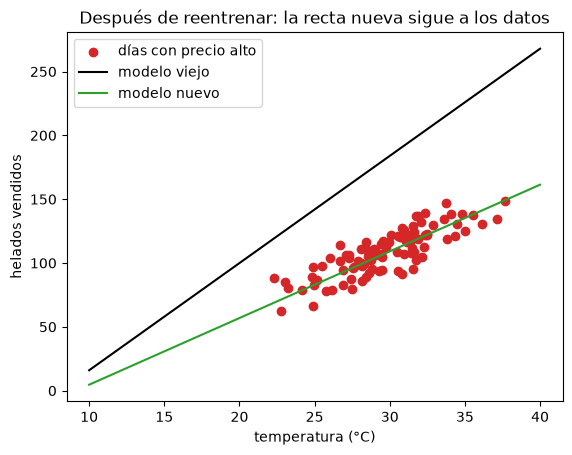

In [22]:
plt.scatter(temp_prueba, ventas_prueba, color="tab:red", label="días con precio alto")       # datos reales
plt.plot(x, modelo.predict(x.reshape(-1, 1)), color="black", label="modelo viejo")          # recta vieja
plt.plot(x, modelo_nuevo.predict(x.reshape(-1, 1)), color="tab:green", label="modelo nuevo")  # recta nueva
plt.xlabel("temperatura (°C)")
plt.ylabel("helados vendidos")
plt.title("Después de reentrenar: la recta nueva sigue a los datos")
plt.legend()
plt.show()

---
## Paso 6 · Un revisor automático

Juntamos las dos revisiones en una función. En una empresa, algo así se ejecuta solo cada día o cada semana.

- **Data drift:** prueba KS entre las temperaturas nuevas y las del entrenamiento.
- **Concept drift:** ¿el error es más del doble que el de referencia?

In [23]:
def revisar(temp_nuevas, ventas_nuevas):
    p_valor = ks_2samp(temp_primavera, temp_nuevas).pvalue                  # ¿cambiaron los datos?
    error = mean_absolute_error(ventas_nuevas,                              # ¿cuánto se equivoca el modelo?
                                modelo.predict(temp_nuevas.reshape(-1, 1)))
    data_drift = p_valor < 0.05                                             # True si cambiaron los datos
    concept_drift = error > 2 * error_referencia                            # True si el error se duplicó
    if concept_drift:                                                       # lo más grave primero
        accion = "REENTRENAR"
    elif data_drift:
        accion = "vigilar"
    else:
        accion = "todo bien"
    print(f"data drift: {'sí' if data_drift else 'no'} · error {error:5.1f} · "
          f"concept drift: {'sí' if concept_drift else 'no'} → {accion}")

print("Primavera:          ", end=""); revisar(temp_primavera, ventas_primavera)   # los datos de entrenamiento
print("Verano:             ", end=""); revisar(temp_verano, ventas_verano)         # data drift
print("Verano precio alto: ", end=""); revisar(temp_precio, ventas_precio)         # concept drift

Primavera:          data drift: no · error   7.8 · concept drift: no → todo bien
Verano:             data drift: sí · error   8.3 · concept drift: no → vigilar
Verano precio alto: data drift: sí · error  74.4 · concept drift: sí → REENTRENAR


En el último caso aparecen los dos: la temperatura sigue siendo de verano (data drift, como antes) **y además** cambió la regla (concept drift). Lo que decide la acción es el concept drift: el modelo dejó de acertar.

---
## Resumen

| | Verano | Precio alto |
|---|---|---|
| ¿Cambiaron los datos (temperatura)? | **sí** | no (respecto del verano) |
| ¿Cambió la regla (temperatura → ventas)? | no | **sí** |
| Tipo de drift | **data drift** | **concept drift** |
| ¿El modelo sigue acertando? | sí (error ≈ 8 helados) | no (error ≈ 74 helados) |
| ¿Qué hacer? | vigilar | reentrenar |

**Para recordar:**
1. **Data drift** = cambian los datos de entrada. Se ve rápido, pero no siempre daña al modelo.
2. **Concept drift** = cambia la regla. No se ve mirando solo los datos de entrada: hay que comparar las predicciones con la realidad.
3. Siempre guarden una **referencia** (los datos y el error del entrenamiento) para tener contra qué comparar.

---
## Ejercicios

**1.** Cambien la temperatura promedio del verano de 30 °C a 22 °C. ¿La prueba KS detecta el cambio? ¿Y el modelo sigue acertando?

In [ ]:
temp_ej1 = rng.normal(22, 3, 100)          # verano más suave: 22 °C en promedio
ventas_ej1 = vender_helados(temp_ej1)      # regla normal
# TODO: usen revisar(temp_ej1, ventas_ej1) y comenten el resultado

**2.** Imaginen que el precio **baja**: cada grado vende 10 helados (en vez de 8). Escriban esas ventas como `10 * temp_ej2 - 60 + ruido` y revisen. ¿Qué tipo de drift es?

In [ ]:
temp_ej2 = rng.normal(20, 3, 100)                          # primavera otra vez
ventas_ej2 = 10 * temp_ej2 - 60 + rng.normal(0, 10, 100)   # regla nueva: 10 helados por grado
# TODO: usen revisar(temp_ej2, ventas_ej2)

**3.** En el Paso 5 reentrenamos solo con los días de precio alto. Reentrenen **mezclando** primavera y precio alto, y comparen el error con `temp_prueba` y `ventas_prueba`. ¿Cuál modelo es mejor? ¿Por qué?

*Pista:* `np.concatenate([temp_primavera, temp_precio])` junta dos listas.

In [ ]:
# TODO: entrenen un modelo con los datos mezclados y calculen su error en temp_prueba / ventas_prueba

---
### Respuestas para el docente (borrar antes de compartir)

1. KS **sí** detecta el cambio (p-valor < 0.05) aunque son solo 2 °C, pero el error sigue bajo: es data drift inofensivo → vigilar.
2. KS dice que los datos **no** cambiaron (es primavera otra vez), pero el error sube mucho: es **concept drift** (la regla cambió hacia arriba) → reentrenar.
3. El modelo mezclado se equivoca más (≈ 11 helados contra ≈ 8): los datos de primavera enseñan la regla vieja. Después de un concept drift conviene entrenar con datos del mundo nuevo.